# P0：RQ2 下游出发延误预测与解释

研究问题：上游飞机实际到达后，能否预测下游出发延误？P0 使用三个朴素基线与计划信息 G0 线性回归。此页从该轮完整预测与指标归档读取结果，不重新训练。

In [1]:
ROOT = __import__('pathlib').Path.cwd()
RUN_DIR = ROOT / 'experiments/runs/R0006'

In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

if "ROOT" not in globals():
    ROOT = Path.cwd()
    while not (ROOT / "scripts/build_features.py").exists():
        if ROOT.parent == ROOT:
            raise RuntimeError("请在 Airline-delay 仓库中运行 Notebook")
        ROOT = ROOT.parent
if "RUN_DIR" not in globals():
    candidates = [p for p in (ROOT / "experiments/runs").glob("R*")
                  if (p / "metrics.csv").exists() and (p / "eda_summary.json").exists()
                  and (p / "rq1_summary.json").exists()]
    if not candidates:
        raise RuntimeError("请先运行 P0 开发分析，或手动设置 RUN_DIR")
    RUN_DIR = max(candidates, key=lambda p: int(p.name[1:]))
TABLES = RUN_DIR / "tables"
FIGURES = RUN_DIR / "figures"
def table(name):
    return pd.read_csv(TABLES / name)
def figure(name):
    display(Image(filename=str(FIGURES / name)))
def receipt(name):
    return json.loads((RUN_DIR / name).read_text(encoding="utf-8"))
display(Markdown(f"**归档运行：{RUN_DIR.name}**。本 Notebook 读取该轮表格与图，不重新拟合模型。"))

**归档运行：R0006**。本 Notebook 读取该轮表格与图，不重新拟合模型。

## 1. 预测时点、时间折与标签成熟

固定 UTC 前向验证：4 月训练→5 月验证；4–5 月训练→6 月验证；4–6 月训练→7 月验证。预测时间窗为半开区间。训练记录不仅预测时点须早于截止，实际出发标签也须严格早于该折截止；在月初同刻才成熟的标签不能用于训练。8 月不参与本轮开发。

In [3]:
splits = pd.read_csv(RUN_DIR / "split_audit.csv")
display(splits)
model_manifest = receipt("model_manifest.json")
display(pd.DataFrame([{k: model_manifest[k] for k in ["evaluation_rows", "evaluation_ids_sha256", "split_sha256"]}]))

,fold,train_start,train_end_exclusive,validation_start,validation_end_exclusive,train_rows,validation_rows,excluded_immature_training_labels,max_train_prediction_time,max_train_label_time,min_validation_prediction_time,max_validation_prediction_time,train_id_sha256,validation_id_sha256,train_target_sha256,validation_target_sha256
0,2026-05,2026-04-01T00:00:00+00:00,2026-05-01T00:00:00+00:00,2026-05-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,553140,574571,1544,2026-04-30T23:30:00+00:00,2026-04-30T23:59:00+00:00,2026-05-01T00:00:00+00:00,2026-05-31T23:59:00+00:00,1d9c1c54be72084a627b3865b21fc94e9e93254c332782...,db70eb2f46beff2f44a0d978cce9dbd84b44dbb52b1e50...,5c386d0f0ee1fc6a9a99cf99f6182c2d58579a493e3408...,4127ab7e0a6298fa42539db1bbc74075047d578ec63df3...
1,2026-06,2026-04-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,1127717,561972,1538,2026-05-31T23:36:00+00:00,2026-05-31T23:59:00+00:00,2026-06-01T00:00:00+00:00,2026-06-30T23:59:00+00:00,a90b8697524811822601e389f6dcd6af7155f7a3d71e2a...,e96b8cf52f6698df4b45e9a05b14fa21ebb3e2bc1f61ab...,92e5c3e7e1944ae98416f68e3b23b51c470d00762f1187...,6f0f88b0e09b752f77db4007c4375cfdf7bdfbf30355f4...
2,2026-07,2026-04-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,2026-08-01T00:00:00+00:00,1689573,570548,1654,2026-06-30T23:29:00+00:00,2026-06-30T23:59:00+00:00,2026-07-01T00:00:00+00:00,2026-07-31T23:59:00+00:00,620f6bd533a0293c182707e431ac65134e28da7eb60cc3...,df7fcbba5aaedaa4b8e9d6a590fa9bfaf19de5ff4b9070...,3f44149b050fa6f382963ad2b9afca69b645b2bb61692b...,0533c6befc1f7beac3ebae6d421b6945f82253dc78b655...


,evaluation_rows,evaluation_ids_sha256,split_sha256
0,1707091,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...


## 2. G0 特征和朴素基线

G0 仅包含机场、航线、航司、航程、计划飞行时长、星期、计划出发小时、计划周转。上游到达延误仅用于本轮 carry-forward 业务基线，还未加入 G0。实际地面时间、下游实际出发和结果字段禁止入模。训练均值/中位数在每折训练段估计；填补、类别合并、编码和缩放均在该训练段拟合。

In [4]:
display(pd.DataFrame({"G0特征": model_manifest["features"]}))
display(pd.DataFrame([model_manifest["effective_preprocessing"]]))

,G0特征
0,airport_id
1,route
2,downstream_airline
3,downstream_distance
4,downstream_crs_elapsed_time
5,downstream_day_of_week
6,downstream_sched_hour
7,scheduled_turnaround_minutes


,min_frequency,drop,sparse,categorical_imputation,numeric_imputation,numeric_scaling,unknown_categories
0,20,first,True,constant __MISSING__; keep_empty_features=True,median; add_indicator=True; keep_empty_feature...,"StandardScaler(with_mean=False), fixed across ...",infrequent_if_exist


## 3. 每折与加权整体误差

主要指标为 MAE，RMSE 反映大误差的影响。所有模型统一先将负预测截断为零。整体 MAE 使用所有验证记录的绝对误差总量除以总样本数，整体 RMSE 也由平方误差总量计算；不是三个折指标的简单平均。以下结果只用于建立初始参照。

,model,fold,n,mae,rmse,target_ge15_share
0,training_mean,2026-05,574571,17.969705,43.443239,0.207785
395,training_median,2026-05,574571,13.209259,45.383891,0.207785
790,carry_forward,2026-05,574571,14.173169,49.267137,0.207785
1185,g0_linear,2026-05,574571,17.021161,43.097816,0.207785
1580,training_mean,2026-06,561972,21.068890,50.817858,0.247952
1979,training_median,2026-06,561972,16.995806,53.396380,0.247952
2378,carry_forward,2026-06,561972,17.543874,56.830990,0.247952
2777,g0_linear,2026-06,561972,19.667731,50.034227,0.247952
3176,training_mean,2026-07,570548,23.718273,57.589119,0.272265
3576,training_median,2026-07,570548,19.678702,60.592404,0.272265


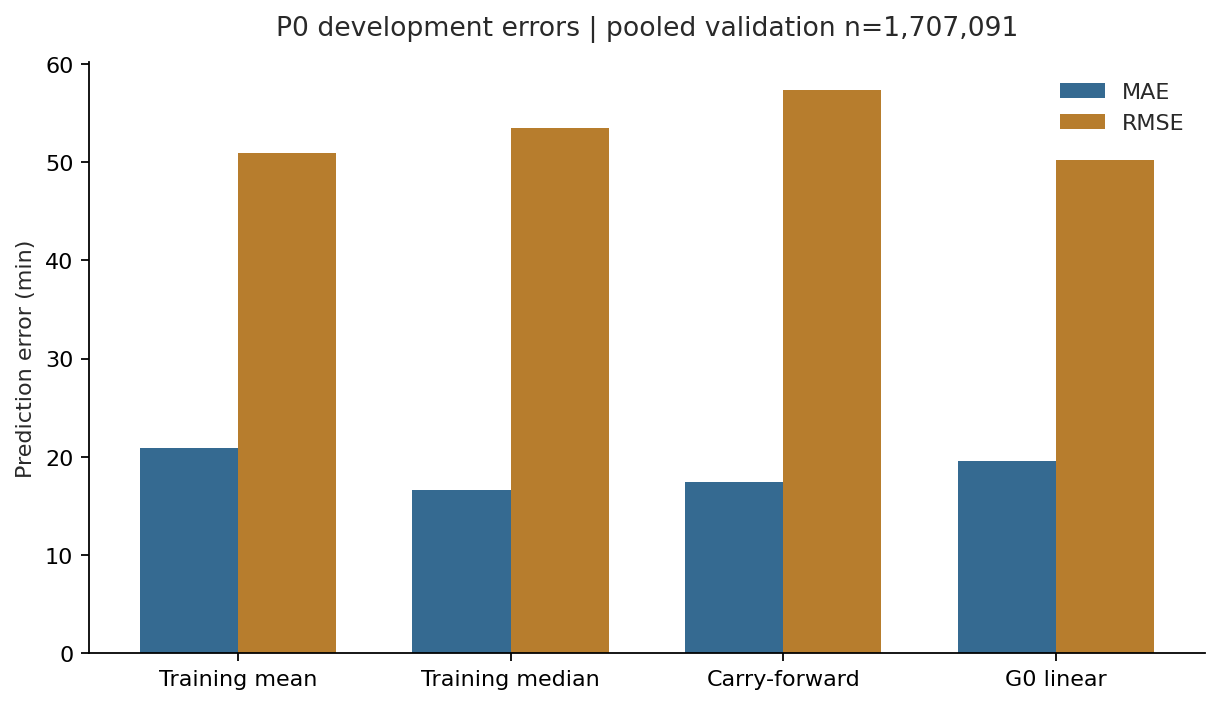

,n,mae,rmse,MAE改善_vs_carry_forward_分钟
model,,,,
carry_forward,1707091,17.425608,57.330724,0.000000
g0_linear,1707091,19.573829,50.235168,-2.148221
training_mean,1707091,20.911252,50.929578,-3.485645
training_median,1707091,16.618017,53.468967,0.807590


In [5]:
metrics = pd.read_csv(RUN_DIR / "metrics.csv")
main = metrics.loc[metrics["group"].eq("all")]
display(main[["model", "fold", "n", "mae", "rmse", "target_ge15_share"]])
figure("rq2_metric_comparison.png")
pooled = main.loc[main.fold.eq("overall")].set_index("model")
comparison = pooled[["n", "mae", "rmse"]].copy()
comparison["MAE改善_vs_carry_forward_分钟"] = pooled.loc["carry_forward", "mae"] - comparison.mae
display(comparison)

## 4. 严重延误、隔夜及运行分组

普通/严重组按真实非负目标预定义为 <60 / ≥60 分钟。这些是结果人群的误差分层，不能作为训练后筛选有利人群的方法。隔夜、机场、航司、星期和计划小时同时给出样本数；小样本组误差应谨慎解读。

In [6]:
overall = metrics.loc[metrics.fold.eq("overall")]
for group in ["severity", "overnight", "day_of_week", "scheduled_hour"]:
    display(Markdown(f"**{group}**"))
    display(overall.loc[overall["group"].eq(group), ["model", "value", "n", "mae", "rmse"]])
for group in ["airport", "airline"]:
    display(Markdown(f"**{group}（G0样本最多20组）**"))
    display(overall.loc[overall["group"].eq(group) & overall.model.eq("g0_linear"), ["value", "n", "mae", "rmse"]].sort_values("n", ascending=False).head(20))

**severity**

,model,value,n,mae,rmse
5177,carry_forward,ordinary_lt60,1574341,12.426625,39.098450
5178,carry_forward,severe_ge60,132750,76.710750,155.361423
5580,g0_linear,ordinary_lt60,1574341,11.482366,14.517260
5581,g0_linear,severe_ge60,132750,115.534076,173.067451
5983,training_mean,ordinary_lt60,1574341,12.547824,14.185081
5984,training_mean,severe_ge60,132750,120.096846,175.979509
6386,training_median,ordinary_lt60,1574341,6.803280,14.576591
6387,training_median,severe_ge60,132750,133.015330,185.052407


**overnight**

,model,value,n,mae,rmse
5151,carry_forward,False,1377745,13.105141,46.287583
5152,carry_forward,True,329346,35.499311,89.853296
5554,g0_linear,False,1377745,21.083997,51.106011
5555,g0_linear,True,329346,13.256382,46.415391
5957,training_mean,False,1377745,21.745577,51.909110
5958,training_mean,True,329346,17.421042,46.609275
6360,training_median,False,1377745,18.540974,54.857502
6361,training_median,True,329346,8.573761,47.219731


**day_of_week**

...

,model,value,n,mae,rmse
5153,carry_forward,0,2769,21.368003,59.096031
5154,carry_forward,1,844,17.338863,66.786833
5155,carry_forward,10,110303,10.439100,45.342340
5156,carry_forward,11,104999,10.824522,48.963479
5157,carry_forward,12,100945,12.045034,57.118649
...,...,...,...,...,...
6381,training_median,5,50291,6.543079,40.640844
6382,training_median,6,118864,7.003618,47.953169
6383,training_median,7,128852,7.335773,41.314174
6384,training_median,8,113499,7.486057,35.658440


**airport（G0样本最多20组）**

,value,n,mae,rmse
5436,13930,85951,21.449539,46.515744
5281,11292,79253,17.339088,39.849909
5211,10397,76296,18.235001,42.366244
5282,11298,72464,22.201453,46.410230
5378,12892,46444,15.932292,36.048519
5448,14107,45714,16.878593,40.003321
5493,14747,44035,14.712003,38.734461
5261,11057,41448,19.724827,45.798411
5376,12889,40458,19.020422,39.979661
5495,14771,37179,23.202074,50.187916


**airline（G0样本最多20组）**

,value,n,mae,rmse
5190,WN,349743,17.526715,31.950479
5182,DL,259774,16.565622,43.061701
5179,AA,232903,25.410582,70.595756
5188,OO,211816,19.322790,48.723432
5189,UA,201614,18.923197,49.836677
5180,AS,87165,12.733825,27.275924
5191,YX,84426,17.440536,45.418300
5185,MQ,81684,17.688082,47.807636
5181,B6,55338,22.529982,55.265980
5187,OH,54608,28.536467,78.833725


## 5. 下一轮比较与证据

每折完整预测在 predictions/，模型在 models/，实际评估 connection_id 在 evaluation_ids.csv.gz。后续添加 G1、机型、机场运行与天气时使用同一评估 ID、相同时间折和线性模型设置，逐轮只改变一项研究因素。当前没有天气增益、复杂模型增益或最终 8 月测试结论。